# The weather vane: a model that learns a true pattern and still fails
**Decoding Causality, Season 2, Episode 1 workshop** · [Open in Colab](https://colab.research.google.com/github/pozapas/pozapas.github.io/blob/main/static/podcasts/decoding-causality/notebooks/S2E01_weather_vane.ipynb)

We use real data from the light tunnel built by Gamella, Peters and Bühlmann at ETH Zürich (Nature Machine Intelligence, 2025). The data is open under CC BY 4.0 at causalchamber.org.

The tunnel has a red, green and blue light source at one end, two rotating polarizers, and light sensors before, between and after them. It also measures the electric current the light source draws.

Here's the plan:
1. **Watch.** Learn a pattern from normal data.
2. **Predict.** Guess what happens when someone changes the system.
3. **Run.** Compare the guess, the model and the real measurement.

In [1]:
# Setup. In Colab this installs the package. The dataset is about 4 MB.
import importlib.util, subprocess, sys
if importlib.util.find_spec("causalchamber") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "causalchamber"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from causalchamber.datasets import Dataset

data = Dataset("lt_interventions_standard_v1", root="./data", download=True)
def load(name):
    return data.get_experiment(name=name).as_pandas_dataframe()

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})
MAROON, GOLD = "#501214", "#c9a25a"


Citation
--------

If you use our datasets, simulators or Remote Lab for your work, please consider citing:

﻿@article{gamella2025chamber,
  author={Gamella, Juan L. and Peters, Jonas and B{"u}hlmann, Peter},
  title={Causal chambers as a real-world physical testbed for {AI} methodology},
  journal={Nature Machine Intelligence},
  doi={10.1038/s42256-024-00964-x},
  year={2025},
}


Support & feedback
------------------

If you encounter bugs o have feedback, please write us an email at

  support@causalchamber.ai

or leave an issue at

  https://github.com/juangamella/causal-chamber-package/issues

If you are a Remote Lab subscriber, contact us directly through any of
the provided support channels.


Fetching list of available datasets from
  https://causalchamber.s3.eu-central-1.amazonaws.com/downloadables/directory.yaml ...

 done.
Dataset lt_interventions_standard_v1 found in "data\lt_interventions_standard_v1".


## 1. Watch
In the normal data, every setting is chosen at random, 10,000 times. We look at two readings:
- **current**: what the meter says about the current drawn by the light source
- **ir_1**: the first light sensor, before the polarizers

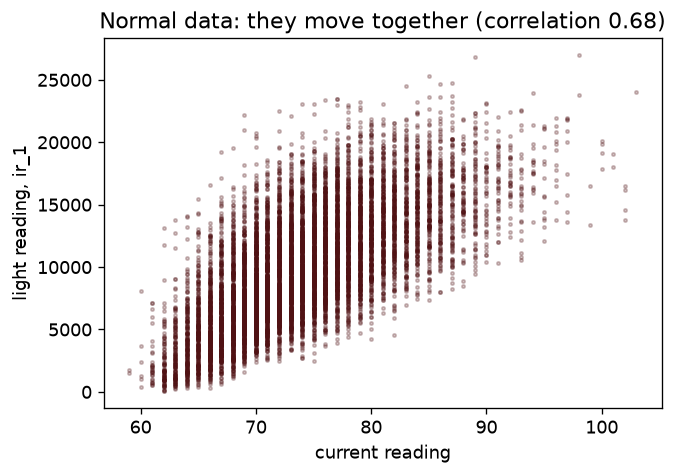

In [2]:
ref = load("uniform_reference")
r = ref["current"].corr(ref["ir_1"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(ref["current"], ref["ir_1"], s=4, alpha=0.25, color=MAROON)
ax.set_xlabel("current reading"); ax.set_ylabel("light reading, ir_1")
ax.set_title(f"Normal data: they move together (correlation {r:.2f})")
plt.show()

In [3]:
# Train the simplest possible model: predict the light from the current reading
model = LinearRegression().fit(ref[["current"]], ref["ir_1"])
print(f"R squared on the normal data: {model.score(ref[['current']], ref['ir_1']):.2f}")
print(f"Each extra unit of current reading predicts {model.coef_[0]:.0f} more units of light")

R squared on the normal data: 0.47
Each extra unit of current reading predicts 475 more units of light


## 2. Predict, before you run anything
The researchers **recalibrate the current meter**. They change its reference voltage, and nothing else. The lamp is exactly the same.

The meter reading roughly doubles, from about 74 to about 144.

**Your prediction:**
- What happens to the real light reading?
- What will our model predict?

Write your guess down first.

In [4]:
recal = load("uniform_v_c_mid")
pred = model.predict(recal[["current"]])
print(f"current reading:  normal {ref['current'].mean():6.0f}   after recalibration {recal['current'].mean():6.0f}")
print(f"real light:       normal {ref['ir_1'].mean():6.0f}   after recalibration {recal['ir_1'].mean():6.0f}")
print(f"model predicts:                     {pred.mean():6.0f}")

current reading:  normal     74   after recalibration    144
real light:       normal  10092   after recalibration   9745
model predicts:                      43407


The meter moved, but the light didn't. The model expected about four times more light.

The model wasn't wrong about the pattern. In the normal data, the LED brightness drives **both** readings, so they rise together. The current reading only *reports* the light source. Recalibrating the meter is turning the weather vane by hand.

## 3. Predict again
This time the researchers **turn up the red LED**, a real cause of both readings. What happens to the current, the light and the model's prediction?

In [5]:
red = load("uniform_red_strong")
pred_red = model.predict(red[["current"]])
print(f"current reading:  normal {ref['current'].mean():6.0f}   red turned up {red['current'].mean():6.0f}")
print(f"real light:       normal {ref['ir_1'].mean():6.0f}   red turned up {red['ir_1'].mean():6.0f}")
print(f"model predicts:                     {pred_red.mean():6.0f}")

current reading:  normal     74   red turned up     96
real light:       normal  10092   red turned up  33479
model predicts:                      20337


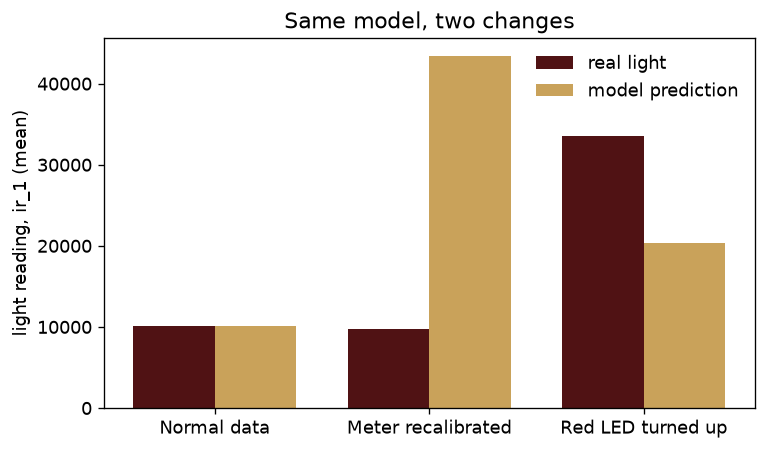

In [6]:
rows = [("Normal data", ref, model.predict(ref[["current"]])),
        ("Meter recalibrated", recal, pred),
        ("Red LED turned up", red, pred_red)]
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(rows)); w = 0.38
ax.bar(x - w/2, [d["ir_1"].mean() for _, d, _ in rows], w, color=MAROON, label="real light")
ax.bar(x + w/2, [p.mean() for _, _, p in rows], w, color=GOLD, label="model prediction")
ax.set_xticks(x, [n for n, _, _ in rows]); ax.set_ylabel("light reading, ir_1 (mean)")
ax.set_title("Same model, two changes"); ax.legend(frameon=False)
plt.show()

## 3b. How sure are we? Confidence intervals
A difference in means with a 95% interval, using a two-sample normal approximation.

In [7]:
def change(exp):
    a, b = ref["ir_1"], exp["ir_1"]
    d = b.mean() - a.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return d, d - 1.96 * se, d + 1.96 * se

for name, exp in [("meter recalibrated", recal), ("red LED turned up", red)]:
    d, lo, hi = change(exp)
    implied = model.predict(exp[["current"]]).mean() - ref["ir_1"].mean()
    print(f"{name:20s} measured change {d:8.0f}  (95% CI {lo:.0f} to {hi:.0f})   model implies {implied:8.0f}")

meter recalibrated   measured change     -348  (95% CI -646 to -50)   model implies    33315
red LED turned up    measured change    23386  (95% CI 23099 to 23673)   model implies    10244


## 3c. Three colours, one meter reading
Turn up each LED separately. The meter moves the same amount; the light does not.

In [8]:
green, blue = load("uniform_green_strong"), load("uniform_blue_strong")
for name, exp in [("red", red), ("green", green), ("blue", blue)]:
    print(f"{name:6s} current {exp['current'].mean():5.1f}   light {exp['ir_1'].mean():7.0f}   model {model.predict(exp[['current']]).mean():7.0f}")

# Why: how each LED drives the meter and the light sensor in the normal data
rgb = ["red", "green", "blue"]
for target in ["current", "ir_1"]:
    fit = LinearRegression().fit(ref[rgb], ref[target])
    print(target, "weights R, G, B:", np.round(fit.coef_, 2), " R squared", round(fit.score(ref[rgb], ref[target]), 2))

red    current  95.8   light   33479   model   20337
green  current  96.0   light   25817   model   20446
blue   current  96.4   light   20494   model   20636
current weights R, G, B: [0.12 0.12 0.12]  R squared 0.58
ir_1 weights R, G, B: [142.71  88.49  58.19]  R squared 0.92


## 3d. All interventions at a glance
For each experiment, the measured change in light and the change the model implies.

In [9]:
experiments = {
    "uniform_v_c_mid": "meter reference voltage, mid", "uniform_v_c_strong": "meter reference voltage, strong",
    "uniform_osr_c_strong": "meter oversampling, strong", "uniform_red_strong": "red LED, strong",
    "uniform_green_strong": "green LED, strong", "uniform_blue_strong": "blue LED, strong",
    "uniform_t_ir_1_strong": "sensor 1 exposure, strong", "uniform_diode_ir_1_strong": "sensor 1 photodiode, small",
    "uniform_pol_1_strong": "polarizer 1 angle, strong"}
rows = []
for key, label in experiments.items():
    exp = load(key)
    d, lo, hi = change(exp)
    implied = model.predict(exp[["current"]]).mean() - ref["ir_1"].mean()
    rows.append({"intervention": label, "measured": round(d), "CI low": round(lo), "CI high": round(hi), "model implies": round(implied)})
pd.DataFrame(rows)

,intervention,measured,CI low,CI high,model implies
0,"meter reference voltage, mid",-348,-646,-50,33315
1,"meter reference voltage, strong",-126,-421,170,126340
2,"meter oversampling, strong",244,-56,544,117
3,"red LED, strong",23386,23099,23673,10244
4,"green LED, strong",15725,15444,16005,10354
5,"blue LED, strong",10401,10116,10686,10544
6,"sensor 1 exposure, strong",-8871,-8969,-8773,-244
7,"sensor 1 photodiode, small",-7259,-7381,-7138,43
8,"polarizer 1 angle, strong",-142,-442,157,35


## 4. The wiring the model never saw
The researchers know the true causal diagram because they built the device. A simplified part of it:

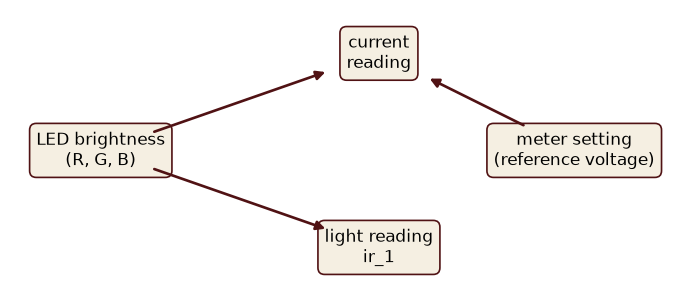

In [10]:
fig, ax = plt.subplots(figsize=(7, 3)); ax.axis("off")
nodes = {"led": ("LED brightness\n(R, G, B)", 0.15, 0.5),
         "cur": ("current\nreading", 0.62, 0.85),
         "ir1": ("light reading\nir_1", 0.62, 0.15),
         "set": ("meter setting\n(reference voltage)", 0.95, 0.5)}
for label, x0, y0 in nodes.values():
    ax.text(x0, y0, label, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f5efe2", ec=MAROON))
def arrow(a, b):
    ax.annotate("", xy=nodes[b][1:], xytext=nodes[a][1:],
                arrowprops=dict(arrowstyle="-|>", color=MAROON, lw=1.6, shrinkA=34, shrinkB=34))
arrow("led", "cur"); arrow("led", "ir1"); arrow("set", "cur")
ax.set_xlim(0, 1.1); ax.set_ylim(0, 1); plt.show()

There's no arrow from the current reading to the light. Both share one cause, the LED brightness.
- **Changing the LED** goes through a real causal path, so the pattern roughly holds.
- **Changing the meter setting** only touches the reading, so the pattern breaks.

From the watching data alone, the model couldn't tell these two changes apart. That's the gap causal AI fills: carry the diagram, and use it to say which changes will matter.

## Try it yourself
The sensor's exposure time is a setting on the light sensor itself. Load `uniform_t_ir_1_strong` and predict before you run: what happens to the current reading, to the light reading, and to the model's prediction?

In [11]:
# Your turn
exp = load("uniform_t_ir_1_strong")
print(f"current reading {exp['current'].mean():.0f}, light reading {exp['ir_1'].mean():.0f}, model predicts {model.predict(exp[['current']]).mean():.0f}")

current reading 74, light reading 1221, model predicts 9848


---
Data: Gamella, Peters and Bühlmann (2025), *Causal chambers as a real-world physical testbed for AI methodology*, Nature Machine Intelligence, doi 10.1038/s42256-024-00964-x. Dataset lt_interventions_standard_v1, CC BY 4.0.